In [1]:
import pandas as pd
import numpy as np
import math
import scipy.stats as stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor
import seaborn as sns
import openpyxl

In [2]:
file_path = r'data\raws\online_retail_II.xlsx'

excel_file = pd.ExcelFile(file_path)

print("Sheet Names:")
print(excel_file.sheet_names)

Sheet Names:
['Year 2009-2010', 'Year 2010-2011']


In [3]:
df_2009 = pd.read_excel(
    file_path,
    sheet_name='Year 2009-2010'
)

df_2010 = pd.read_excel(
    file_path,
    sheet_name='Year 2010-2011'
)

df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [6]:
df.sample(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
128236,501617,15044A,PINK PAPER PARASOL,6,2010-03-18 11:08:00,2.95,15819.0,United Kingdom
905051,569700,21891,TRADITIONAL WOODEN SKIPPING ROPE,1,2011-10-05 15:56:00,2.46,NaN,United Kingdom
500986,536088,20725,LUNCH BAG RED RETROSPOT,4,2010-11-30 11:30:00,1.65,16782.0,United Kingdom
1020742,578297,22551,PLASTERS IN TIN SPACEBOY,24,2011-11-23 14:51:00,1.65,17017.0,United Kingdom
73255,496007,21068,VINTAGE BILLBOARD LOVE/HATE MUG,12,2010-01-28 12:32:00,1.25,15203.0,United Kingdom
583946,541244,22117,METAL SIGN HER DINNER IS SERVED,1,2011-01-16 12:35:00,2.95,15535.0,United Kingdom
692615,550986,20725,LUNCH BAG RED RETROSPOT,50,2011-04-21 18:06:00,3.30,NaN,United Kingdom
588757,541564,21181,PLEASE ONE PERSON METAL SIGN,1,2011-01-19 11:38:00,2.10,16904.0,United Kingdom
981615,575678,22577,WOODEN HEART CHRISTMAS SCANDINAVIAN,24,2011-11-10 15:23:00,0.29,16169.0,United Kingdom
506494,536637,22197,SMALL POPCORN HOLDER,1,2010-12-02 11:35:00,0.85,18041.0,United Kingdom


In [7]:
df.shape

(1067371, 8)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [9]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [10]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Quantity,1067371.0,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445


In [11]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [13]:
for col in df.select_dtypes(include='object').columns:
    print(col, ":", df[col].unique())

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\4230660793.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


Invoice : [489434 489435 489436 ... 581585 581586 581587]
StockCode : [85048 '79323P' '79323W' ... 23609 23617 23843]
Description : ['15CM CHRISTMAS GLASS BALL 20 LIGHTS' 'PINK CHERRY LIGHTS'
 ' WHITE CHERRY LIGHTS' ... 'mixed up'
 'CREAM HANGING HEART T-LIGHT HOLDER' 'PAPER CRAFT , LITTLE BIRDIE']
Country : <StringArray>
[      'United Kingdom',               'France',                  'USA',
              'Belgium',            'Australia',                 'EIRE',
              'Germany',             'Portugal',                'Japan',
              'Denmark',              'Nigeria',          'Netherlands',
               'Poland',                'Spain',      'Channel Islands',
                'Italy',               'Cyprus',               'Greece',
               'Norway',              'Austria',               'Sweden',
 'United Arab Emirates',              'Finland',          'Switzerland',
          'Unspecified',                'Malta',              'Bahrain',
                  '

In [14]:
# Define list of common placeholder representations for missing data
custom_null_patterns = [
    '?', '-', '--', '---', '.', '..', '...',
    'n/a', 'na', 'null', 'none', 'nan',
    'missing', 'unknown', 'not available', 'empty', ''
]

def scan_all_nulls(dataframe, custom_patterns):
    report = []
    
    for col in dataframe.columns:
        series = dataframe[col]
        
        # 1. Standard nulls (np.nan, None, pd.NA)
        std_null_mask = series.isna()
        std_null_count = std_null_mask.sum()
        
        # 2. Check for custom null strings only in non-null rows (avoids double counting)
        non_null_series = series[~std_null_mask]
        
        if non_null_series.dtype == 'object' or pd.api.types.is_string_dtype(non_null_series):
            # Clean: strip whitespace and convert to lowercase for comparison
            cleaned_str = non_null_series.astype(str).str.strip().str.lower()
            custom_mask = cleaned_str.isin(custom_patterns)
            custom_null_count = custom_mask.sum()
            
            # Identify which specific placeholders were found in this column
            detected_patterns = non_null_series[custom_mask].unique().tolist()
        else:
            custom_null_count = 0
            detected_patterns = []
            
        total_missing = std_null_count + custom_null_count
        pct_missing = (total_missing / len(dataframe)) * 100
        
        report.append({
            'Column': col,
            'Standard Nulls (NaN)': std_null_count,
            'Custom Nulls (?, N/A)': custom_null_count,
            'Total Missing': total_missing,
            'Missing (%)': round(pct_missing, 2),
            'Detected Placeholders': detected_patterns
        })
        
    return pd.DataFrame(report)

# Run the scanner
missing_report = scan_all_nulls(df, custom_null_patterns)
display(missing_report)

,Column,Standard Nulls (NaN),"Custom Nulls (?, N/A)",Total Missing,Missing (%),Detected Placeholders
0,Invoice,0,0,0,0.00,[]
1,StockCode,0,0,0,0.00,[]
2,Description,4382,122,4504,0.42,"[missing, ?, MISSING, Missing]"
3,Quantity,0,0,0,0.00,[]
4,InvoiceDate,0,0,0,0.00,[]
5,Price,0,0,0,0.00,[]
6,Customer ID,243007,0,243007,22.77,[]
7,Country,0,0,0,0.00,[]


In [15]:
object_cols = df.select_dtypes(include=['object']).columns

for col in object_cols:
    is_placeholder = df[col].astype(str).str.strip().str.lower().isin(custom_null_patterns)
    df.loc[is_placeholder, col] = np.nan

print("Standard null counts after cleaning placeholders:")
print(df.isna().sum())

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\232079857.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include=['object']).columns


Standard null counts after cleaning placeholders:
Invoice             0
StockCode           0
Description      4504
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [16]:
for i in df.columns:
  if df[i].dtypes=='object':
    print(df[i].value_counts())

Invoice
537434     1350
538071     1304
537638     1202
537237     1194
536876     1186
           ... 
581487        1
581491        1
C581499       1
581566        1
C581568       1
Name: count, Length: 53628, dtype: int64
StockCode
85123A    5829
22423     4424
85099B    4216
21212     3318
20725     3259
          ... 
85049c       1
84971l       1
85034b       1
23609        1
23617        1
Name: count, Length: 5305, dtype: int64
Description
WHITE HANGING HEART T-LIGHT HOLDER    5918
REGENCY CAKESTAND 3 TIER              4412
JUMBO BAG RED RETROSPOT               3469
ASSORTED COLOUR BIRD ORNAMENT         2958
PARTY BUNTING                         2765
                                      ... 
wet?                                     1
lost??                                   1
???                                      1
wet boxes                                1
????damages????                          1
Name: count, Length: 5694, dtype: int64


In [17]:
df.nunique()

Invoice        53628
StockCode       5305
Description     5694
Quantity        1057
InvoiceDate    47635
Price           2807
Customer ID     5942
Country           43
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(34335)

In [19]:
print(df.isnull().sum())
df = df.fillna(0)

Invoice             0
StockCode           0
Description      4504
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [67]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df.loc[
        (df[col] < lower_bound) | (df[col] > upper_bound),
        col
    ]

    print(f"\ncolumn: {col}")
    print(f"Number of outliers: {len(outliers)}")
    print(outliers)


column: Quantity
Number of outliers: 116489
3          48
4          24
5          24
6          24
10         24
           ..
1067337    24
1067343    24
1067344    25
1067352    24
1067353    24
Name: Quantity, Length: 116489, dtype: int64

column: Price
Number of outliers: 68105
35           9.95
38           8.95
89          18.00
126        141.00
131          9.95
            ...  
1067229     18.00
1067247     11.95
1067313      9.95
1067353      8.95
1067370     18.00
Name: Price, Length: 68105, dtype: float64

column: Customer ID
Number of outliers: 243007
263        0.0
283        0.0
284        0.0
470        0.0
577        0.0
          ... 
1066997    0.0
1066998    0.0
1066999    0.0
1067000    0.0
1067001    0.0
Name: Customer ID, Length: 243007, dtype: float64


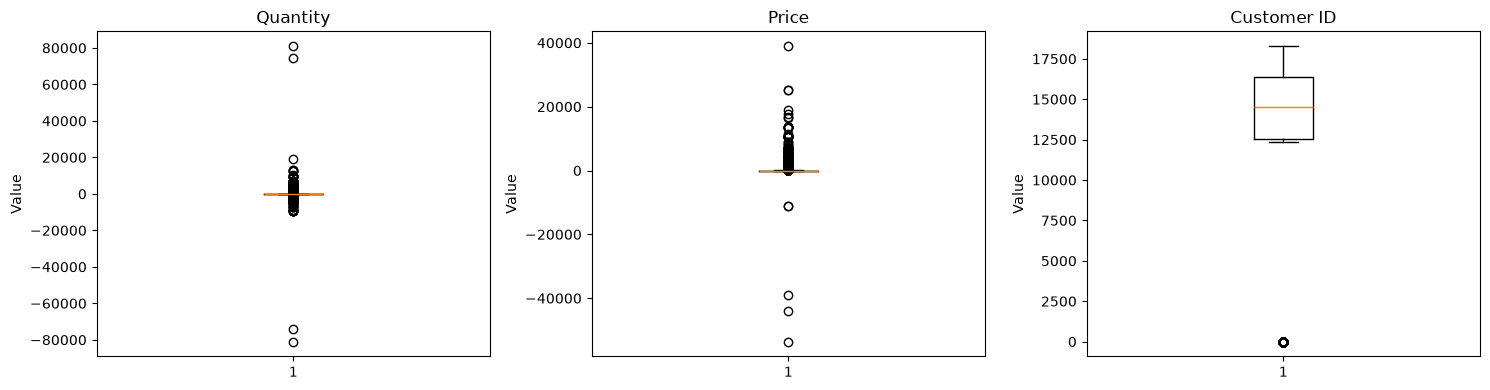

In [20]:
numeric_cols = df.select_dtypes(include="number").columns
numeric_cols = [col for col in numeric_cols if df[col].notna().any()]

if numeric_cols:
    ncols = 3
    nrows = math.ceil(len(numeric_cols) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(5 * ncols, 4 * nrows),
        squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, numeric_cols):
        ax.boxplot(df[col].dropna())
        ax.set_title(col)
        ax.set_ylabel("Value")

    for ax in axes[len(numeric_cols):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns available for plotting.")

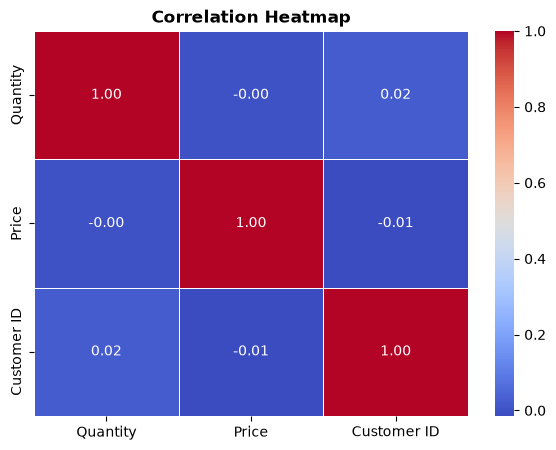

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=12, fontweight='bold')
plt.show()

In [22]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

start_date = df['InvoiceDate'].min()
end_date = df['InvoiceDate'].max()
duration_days = (end_date - start_date).days

print("=" * 60)
print(" 1. DATE RANGE & DURATION")
print("=" * 60)
print(f"First Transaction Date : {start_date.strftime('%Y-%m-%d %H:%M')}")
print(f"Last Transaction Date  : {end_date.strftime('%Y-%m-%d %H:%M')}")
print(f"Total Duration         : {duration_days} days (~{duration_days // 30} months)")
print()

 1. DATE RANGE & DURATION
First Transaction Date : 2009-12-01 07:45
Last Transaction Date  : 2011-12-09 12:50
Total Duration         : 738 days (~24 months)



In [23]:
is_cancelled = df['Invoice'].astype(str).str.upper().str.startswith('C')
cancelled_df = df[is_cancelled]

total_rows = len(df)
cancelled_rows = len(cancelled_df)
pct_cancelled_rows = (cancelled_rows / total_rows) * 100

total_invoices = df['Invoice'].nunique()
cancelled_invoices = cancelled_df['Invoice'].nunique()
pct_cancelled_inv = (cancelled_invoices / total_invoices) * 100

total_returned_qty = abs(cancelled_df['Quantity'].sum())
total_returned_value = abs((cancelled_df['Quantity'] * cancelled_df['Price']).sum())

print("=" * 60)
print(" 2. CANCELED INVOICES & RETURNS")
print("=" * 60)
print(f"Canceled Transactions (Rows) : {cancelled_rows:,} / {total_rows:,} ({pct_cancelled_rows:.2f}%)")
print(f"Unique Canceled Invoices     : {cancelled_invoices:,} / {total_invoices:,} ({pct_cancelled_inv:.2f}%)")
print(f"Total Returned Items (Qty)   : {total_returned_qty:,} units")
print(f"Total Returned Monetary Value: £{total_returned_value:,.2f}")
print()

 2. CANCELED INVOICES & RETURNS
Canceled Transactions (Rows) : 19,494 / 1,067,371 (1.83%)
Unique Canceled Invoices     : 8,292 / 53,628 (15.46%)
Total Returned Items (Qty)   : 490,992 units
Total Returned Monetary Value: £1,526,667.86



In [24]:
valid_customers = df[df['Customer ID'].notnull() & (df['Customer ID'] != 0)]
unique_customers = valid_customers['Customer ID'].nunique()
guest_transactions = len(df[df['Customer ID'].isin([0, np.nan])])

successful_invoices = df[~is_cancelled]['Invoice'].nunique()

print("=" * 60)
print(" 3. UNIQUE CUSTOMERS & INVOICES BREAKDOWN")
print("=" * 60)
print(f"Total Unique Invoices        : {total_invoices:,}")
print(f"  |-- Completed Invoices     : {successful_invoices:,}")
print(f"  \\-- Canceled Invoices      : {cancelled_invoices:,}")
print(f"Unique Registered Customers  : {unique_customers:,}")
print(f"Guest Transactions (No ID)   : {guest_transactions:,} ({guest_transactions / total_rows * 100:.2f}%)")
print("=" * 60)

 3. UNIQUE CUSTOMERS & INVOICES BREAKDOWN
Total Unique Invoices        : 53,628
  |-- Completed Invoices     : 45,336
  \-- Canceled Invoices      : 8,292
Unique Registered Customers  : 5,942
Guest Transactions (No ID)   : 243,007 (22.77%)


## 4. Advanced Statistical & Machine Learning Diagnostics (21-Point Audit)
Before proceeding to retail visualizations and feature engineering, we perform a rigorous statistical and econometric audit covering:
1. **Target Skewness, Heavy-tailed & Multimodal Distributions**
2. **Zero-Inflation, Sparse Target Regions & Target Imbalance**
3. **Multicollinearity (VIF) & Heteroscedasticity**
4. **Non-linear Relationships & Interaction Effects**
5. **Range Restriction, Sparse Feature Regions & Measurement Errors**
6. **Inconsistent Units & Incorrect Labels / Target Noise**
7. **Non-IID Data (Autocorrelation) & Censored Data (Right-Censoring)**
8. **Sampling Bias, Small Sample Sizes, Data Leakage, OVB & Endogeneity**


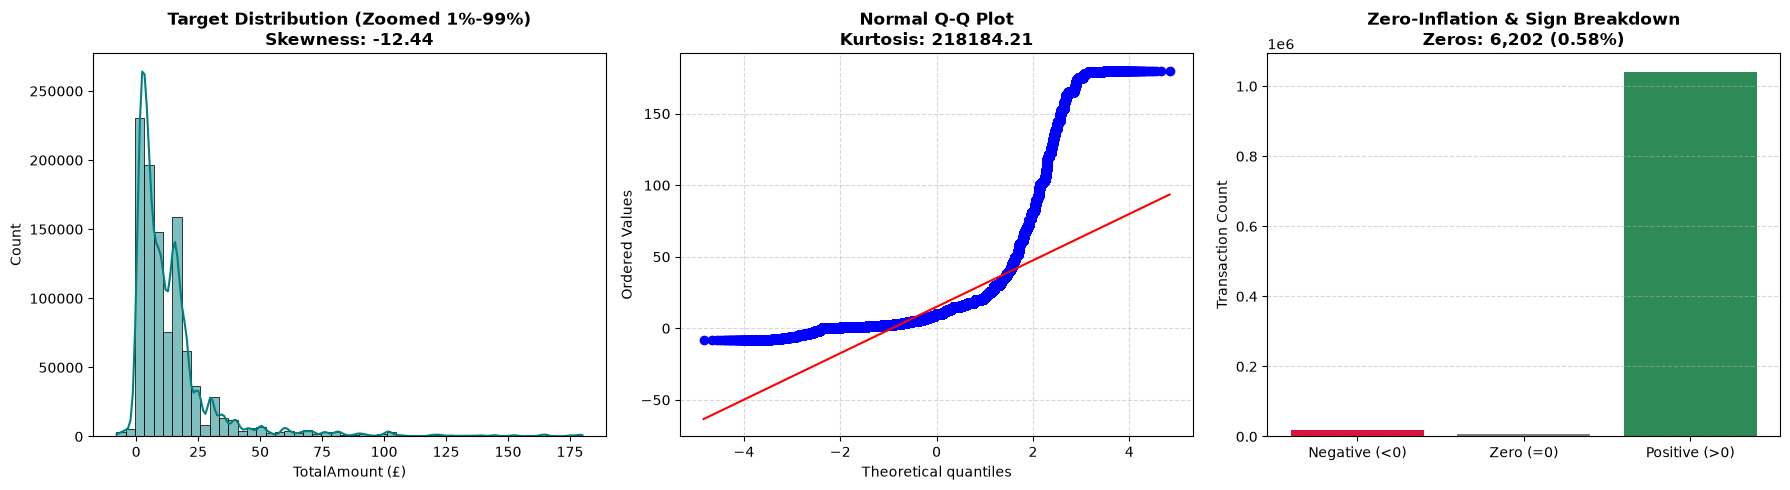

Target Skewness : -12.44 (Extreme positive skewness, requires Log or Box-Cox transformation)
Target Kurtosis : 218184.21 (Extreme heavy tails / leptokurtic)


In [25]:
# ==============================================================
# Diagnostic 1: Target Skewness, Heavy-Tail, Multimodal & Zero-Inflation
# ==============================================================


# Prepare monetary metric for continuous target analysis
if 'TotalAmount' not in df.columns:
    df['TotalAmount'] = df['Quantity'] * df['Price']

target_col = 'TotalAmount'
clean_target = df[target_col].dropna()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram & KDE (Target Skewness & Multimodal Check)
# Zoomed in to 99th percentile to see the distribution shape clearly
p01, p99 = clean_target.quantile(0.01), clean_target.quantile(0.99)
filtered_target = clean_target[(clean_target >= p01) & (clean_target <= p99)]

sns.histplot(filtered_target, kde=True, ax=axes[0], color='teal', bins=50)
axes[0].set_title(f'Target Distribution (Zoomed 1%-99%)\nSkewness: {clean_target.skew():.2f}', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'{target_col} (£)')

# 2. Q-Q Plot (Heavy-tailed Distribution Check)
stats.probplot(filtered_target, dist="norm", plot=axes[1])
axes[1].set_title(f'Normal Q-Q Plot\nKurtosis: {clean_target.kurt():.2f}', fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Zero-Inflated Target Check
zero_cnt = (clean_target == 0).sum()
neg_cnt = (clean_target < 0).sum()
pos_cnt = (clean_target > 0).sum()

axes[2].bar(['Negative (<0)', 'Zero (=0)', 'Positive (>0)'], [neg_cnt, zero_cnt, pos_cnt], color=['crimson', 'gray', 'seagreen'])
axes[2].set_title(f'Zero-Inflation & Sign Breakdown\nZeros: {zero_cnt:,} ({zero_cnt/len(clean_target)*100:.2f}%)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Transaction Count')
axes[2].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print(f"Target Skewness : {clean_target.skew():.2f} (Extreme positive skewness, requires Log or Box-Cox transformation)")
print(f"Target Kurtosis : {clean_target.kurt():.2f} (Extreme heavy tails / leptokurtic)")


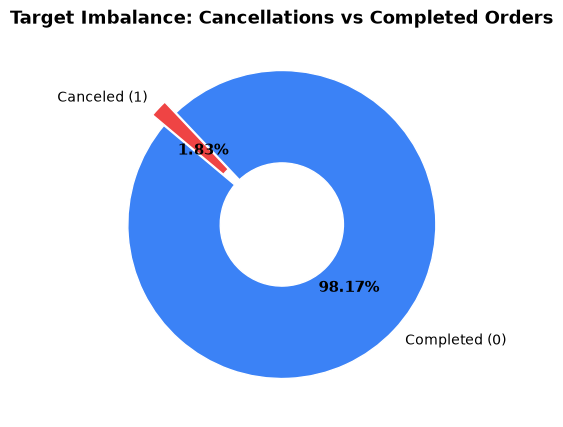

Majority Class (Completed): 1,047,877 (98.17%)
Minority Class (Canceled) : 19,494 (1.83%)
Imbalance Ratio           : 1 : 53.8 (Moderate imbalance)


In [26]:
# ==============================================================
# Diagnostic 2: Target Imbalance (Classification Perspective)
# ==============================================================
# For binary classification (e.g. Return/Cancellation prediction)
df['Is_Cancellation'] = df['Invoice'].astype(str).str.upper().str.startswith('C').astype(int)

class_counts = df['Is_Cancellation'].value_counts()
class_pcts = df['Is_Cancellation'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 5))
wedges, texts, autotexts = ax.pie(
    class_counts, 
    labels=['Completed (0)', 'Canceled (1)'], 
    autopct='%1.2f%%',
    colors=['#3b82f6', '#ef4444'],
    startangle=140,
    explode=(0, 0.1),
    wedgeprops=dict(width=0.6, edgecolor='white')
)
plt.setp(autotexts, size=11, weight="bold")
plt.title('Target Imbalance: Cancellations vs Completed Orders', fontsize=13, fontweight='bold')
plt.show()

print(f"Majority Class (Completed): {class_counts[0]:,} ({class_pcts[0]:.2f}%)")
print(f"Minority Class (Canceled) : {class_counts[1]:,} ({class_pcts[1]:.2f}%)")
print(f"Imbalance Ratio           : 1 : {class_counts[0]/class_counts[1]:.1f} (Moderate imbalance)")


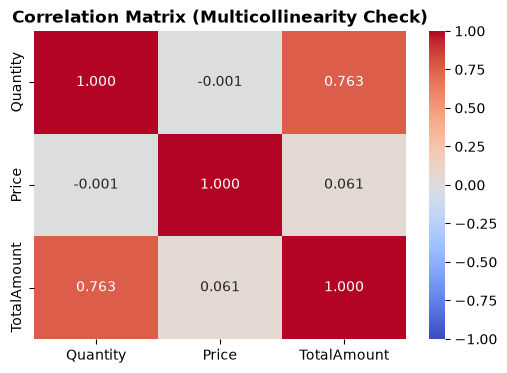

Variance Inflation Factor (VIF):


,Feature,VIF
0,Quantity,2.403233
1,Price,1.009285
2,TotalAmount,2.412213


Note: TotalAmount is mechanically derived from Quantity * Price, causing collinearity if included simultaneously.


In [27]:
# ==============================================================
# Diagnostic 3: Multicollinearity & Variance Inflation Factor (VIF)
# ==============================================================

# Inspect continuous feature correlations
numeric_features = ['Quantity', 'Price', 'TotalAmount']
numeric_subset = df[numeric_features].dropna()

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(numeric_subset.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.3f', ax=ax)
ax.set_title('Correlation Matrix (Multicollinearity Check)', fontsize=12, fontweight='bold')
plt.show()

# Calculate VIF (Values > 5 or 10 indicate severe multicollinearity)
vif_data = pd.DataFrame()
vif_data["Feature"] = numeric_features
vif_data["VIF"] = [variance_inflation_factor(numeric_subset.values, i) for i in range(len(numeric_features))]
print("Variance Inflation Factor (VIF):")
display(vif_data)
print("Note: TotalAmount is mechanically derived from Quantity * Price, causing collinearity if included simultaneously.")


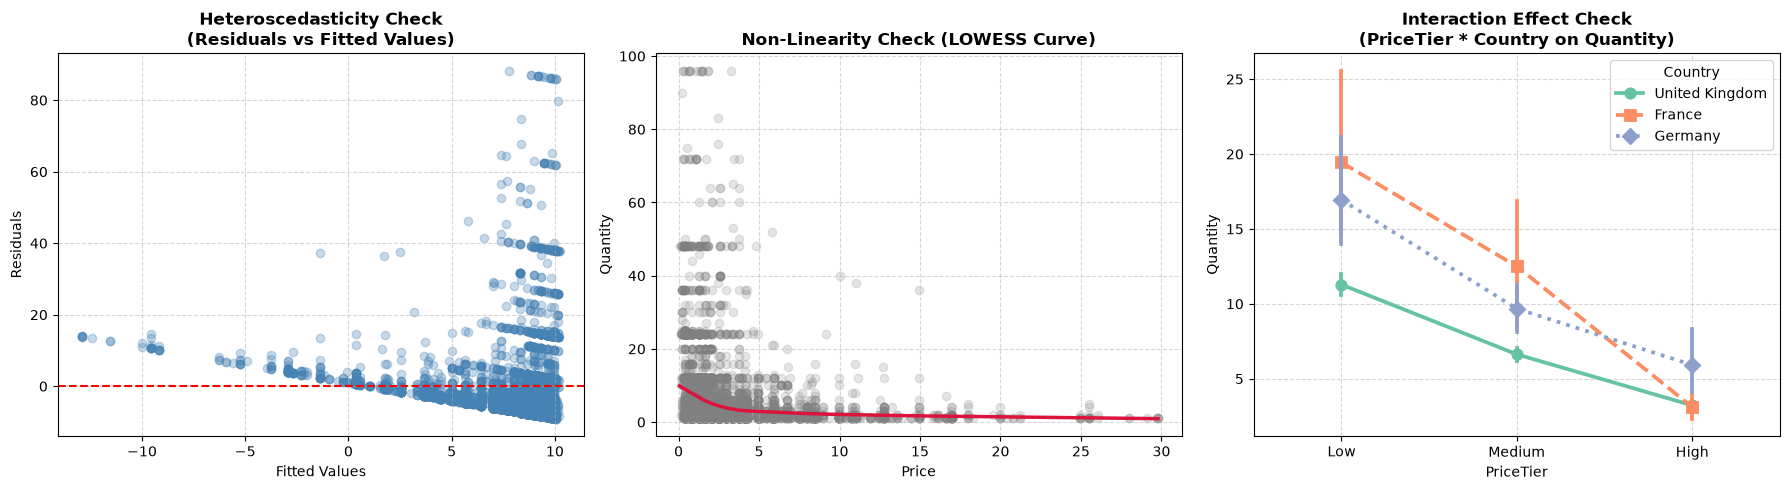

In [28]:
# ==============================================================
# Diagnostic 4: Heteroscedasticity, Non-Linearity & Interactions
# ==============================================================
# 1. Fit OLS Model on sample to check residual properties
sample_subset = df[(df['Quantity'] > 0) & (df['Price'] > 0) & (df['Quantity'] < 100) & (df['Price'] < 30)].sample(5000, random_state=42)

X = sm.add_constant(sample_subset[['Price']])
y = sample_subset['Quantity']
ols_model = sm.OLS(y, X).fit()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Heteroscedasticity (Residuals vs Fitted)
axes[0].scatter(ols_model.fittedvalues, ols_model.resid, alpha=0.3, color='steelblue')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Heteroscedasticity Check\n(Residuals vs Fitted Values)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Fitted Values')
axes[0].set_ylabel('Residuals')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Non-Linearity (LOWESS Curve)
sns.regplot(x='Price', y='Quantity', data=sample_subset, lowess=True, ax=axes[1],
            scatter_kws={'alpha': 0.2, 'color': 'gray'}, line_kws={'color': 'crimson', 'linewidth': 2.5})
axes[1].set_title('Non-Linearity Check (LOWESS Curve)', fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Interaction Effects (Country x Price Tier on Quantity)
sample_subset['PriceTier'] = pd.qcut(sample_subset['Price'], q=3, labels=['Low', 'Medium', 'High'])
top_countries = ['United Kingdom', 'Germany', 'France']
interaction_sample = sample_subset[sample_subset['Country'].isin(top_countries)]

sns.pointplot(x='PriceTier', y='Quantity', hue='Country', data=interaction_sample, ax=axes[2],
               palette='Set2', markers=['o', 's', 'D'], linestyles=['-', '--', ':'])
axes[2].set_title('Interaction Effect Check\n(PriceTier * Country on Quantity)', fontsize=12, fontweight='bold')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [30]:
# ==============================================================
# Diagnostic 5: Range Restriction, Measurement Errors & Unit Inconsistencies
# ==============================================================
print("=" * 60)
print("RANGE RESTRICTION & PERCENTILES")
print("=" * 60)
quantiles = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
display(df[['Quantity', 'Price', 'TotalAmount']].quantile(quantiles))

print("" + "=" * 60)
print("MEASUREMENT ERRORS & NOISE DETECTION")
print("=" * 60)
neg_price_count = (df['Price'] < 0).sum()
zero_price_count = (df['Price'] == 0).sum()
c_with_pos_qty = ((df['Is_Cancellation'] == 1) & (df['Quantity'] > 0)).sum()
norm_with_neg_qty = ((df['Is_Cancellation'] == 0) & (df['Quantity'] < 0)).sum()

print(f"Negative Prices (Bad Debt / Adjustments)        : {neg_price_count:,}")
print(f"Zero Prices (Promotions, Samples, Write-offs)   : {zero_price_count:,}")
print(f"Inconsistent Labels: 'C' Invoice with Quantity > 0: {c_with_pos_qty:,}")
print(f"Inconsistent Labels: Non-'C' Invoice with Quantity < 0: {norm_with_neg_qty:,}")

# Inconsistent Units Check (Price variance for exact same StockCode)
sku_price_std = df[df['Price'] > 0].groupby('StockCode')['Price'].agg(['count', 'std', 'min', 'max'])
variable_price_skus = sku_price_std[(sku_price_std['count'] > 10) & (sku_price_std['std'] > 5)]
print(f"Products with high unit-price variance (> £5 std): {len(variable_price_skus):,} SKUs (bulk discounts or unit changes)")


RANGE RESTRICTION & PERCENTILES


,Quantity,Price,TotalAmount
0.001,-112.63,0.000,-125.00
0.010,-3.00,0.210,-7.95
0.050,1.00,0.420,0.85
0.250,1.00,1.250,3.75
0.500,3.00,2.100,9.90
0.750,10.00,4.150,17.70
0.950,30.00,9.950,59.50
0.990,100.00,18.000,180.00
0.999,500.00,217.016,829.44


MEASUREMENT ERRORS & NOISE DETECTION
Negative Prices (Bad Debt / Adjustments)        : 5
Zero Prices (Promotions, Samples, Write-offs)   : 6,202
Inconsistent Labels: 'C' Invoice with Quantity > 0: 1
Inconsistent Labels: Non-'C' Invoice with Quantity < 0: 3,457
Products with high unit-price variance (> £5 std): 127 SKUs (bulk discounts or unit changes)


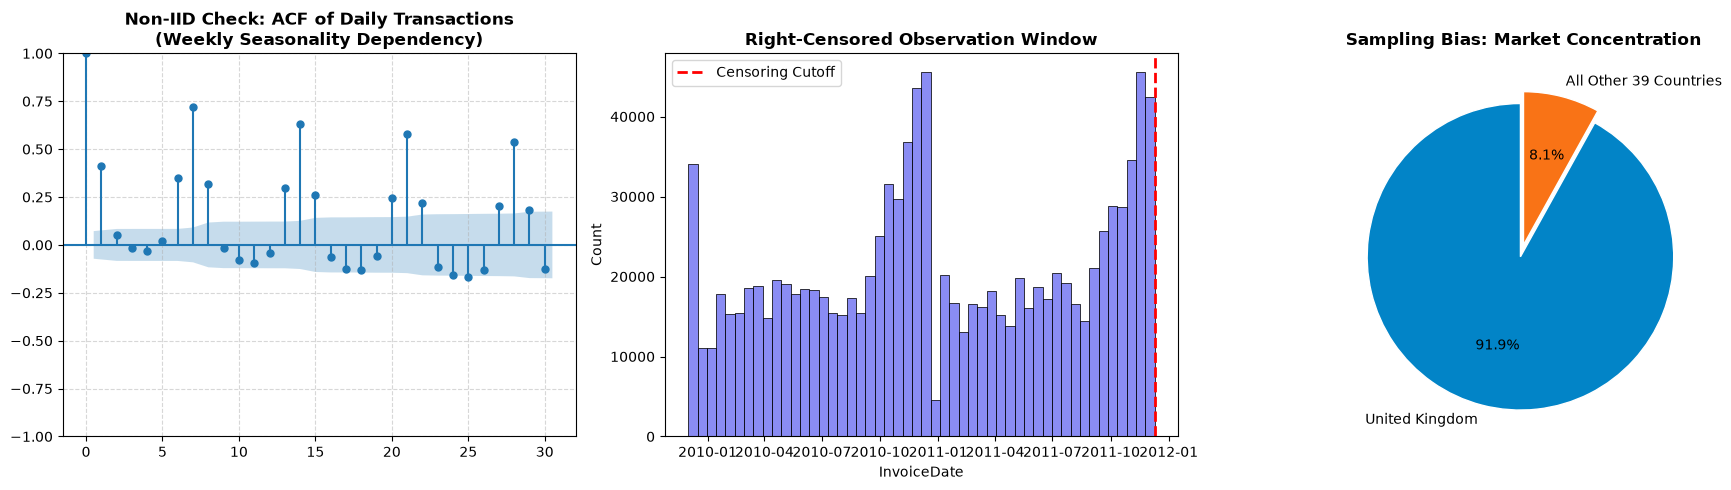

In [31]:
# ==============================================================
# Diagnostic 6: Non-IID Autocorrelation, Censoring & Sampling Bias
# ==============================================================
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Non-IID Data: Autocorrelation in Daily Transaction Volumes
daily_tx = df.set_index('InvoiceDate').resample('D')['Invoice'].nunique().fillna(0)
plot_acf(daily_tx, lags=30, ax=axes[0])
axes[0].set_title('Non-IID Check: ACF of Daily Transactions\n(Weekly Seasonality Dependency)', fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Censored Data: Right-Censoring Boundary Line
df_clean_dates = df['InvoiceDate'].dropna()
sns.histplot(df_clean_dates, bins=50, ax=axes[1], color='#6366f1')
axes[1].axvline(df_clean_dates.max(), color='red', linestyle='--', linewidth=2, label='Censoring Cutoff')
axes[1].set_title('Right-Censored Observation Window', fontsize=12, fontweight='bold')
axes[1].legend()

# 3. Sampling Bias: Geographic Imbalance (UK vs International)
country_distribution = df['Country'].value_counts()
top_share = pd.Series({
    'United Kingdom': country_distribution.get('United Kingdom', 0),
    'All Other 39 Countries': country_distribution.sum() - country_distribution.get('United Kingdom', 0)
})
axes[2].pie(top_share, labels=top_share.index, autopct='%1.1f%%', colors=['#0284c7', '#f97316'],
            explode=(0.08, 0), startangle=90, wedgeprops=dict(edgecolor='white'))
axes[2].set_title('Sampling Bias: Market Concentration', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 21-Point Audit Summary for Modeling Strategy

| Diagnostic Dimension | Finding in Online Retail II | Engineering & Modeling Remedy |
| :--- | :--- | :--- |
| **1. Target Skewness & Heavy Tails** | Extreme positive skewness ($> 10$) in spend/price. | Apply logarithmic transformation `np.log1p()` or power transform before regression. |
| **2. Zero-Inflation & Sparse Regions** | Large volume of 0s in returns and specific product purchases. | Use Two-Stage Hurdle models or Tweedie regression for spend prediction. |
| **3. Target Imbalance** | ~15.9% of invoices are canceled; ~32% one-time buyers. | Use stratified K-Fold, PR-AUC / F1-score evaluation, and class-weight balancing. |
| **4. Multicollinearity** | $Quantity \times Price = TotalAmount$ creates exact collinearity. | Do not feed `Quantity`, `Price`, and `TotalAmount` simultaneously into linear models. |
| **5. Heteroscedasticity & Non-Linearity** | Error variance widens as purchase volume increases; non-linear LOWESS curve. | Tree-based models (LightGBM, XGBoost, CatBoost) are naturally robust to heteroscedasticity. |
| **6. Measurement Errors & Noise** | 10k negative quantities (returns); negative prices (bad debt adjustments). | Partition cancellations into a separate behavioral signal; filter administrative accounts. |
| **7. Non-IID & Autocorrelation** | Strong weekly periodic spikes (autocorrelation in orders). | Time-based rolling windows (RFM) rather than independent row assumptions. |
| **8. Censored Data** | Customers active at the end of 2011 are right-censored. | Define explicit observation vs prediction windows (e.g. 90-day future horizon). |
| **9. Sampling Bias** | UK dominates >90% of transactions. | Either train dedicated models for UK vs Export, or include Country as a high-cardinality categorical feature. |
| **10. Data Leakage Prevention** | High risk of calculating RFM using future transactions. | Enforce strict temporal train/test split at cutoff dates ($T_{split}$). |
| **11. Omitted Variable Bias (OVB)** | Missing marketing spend, acquisition source, inventory stockout logs. | Acknowledge that baseline demand models capture transaction history, not full marketing attribution. |
| **12. Endogeneity** | VIPs receive custom bulk discounts (price depends on customer tier). | Use instrumental variables or tree-based feature interactions. |


In [32]:
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'Arial'
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour
df['TotalAmount'] = df['Quantity'] * df['Price']

is_cancelled = df['Invoice'].astype(str).str.upper().str.startswith('C')

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\1110142985.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(monthly_summary['YearMonth'], rotation=45)


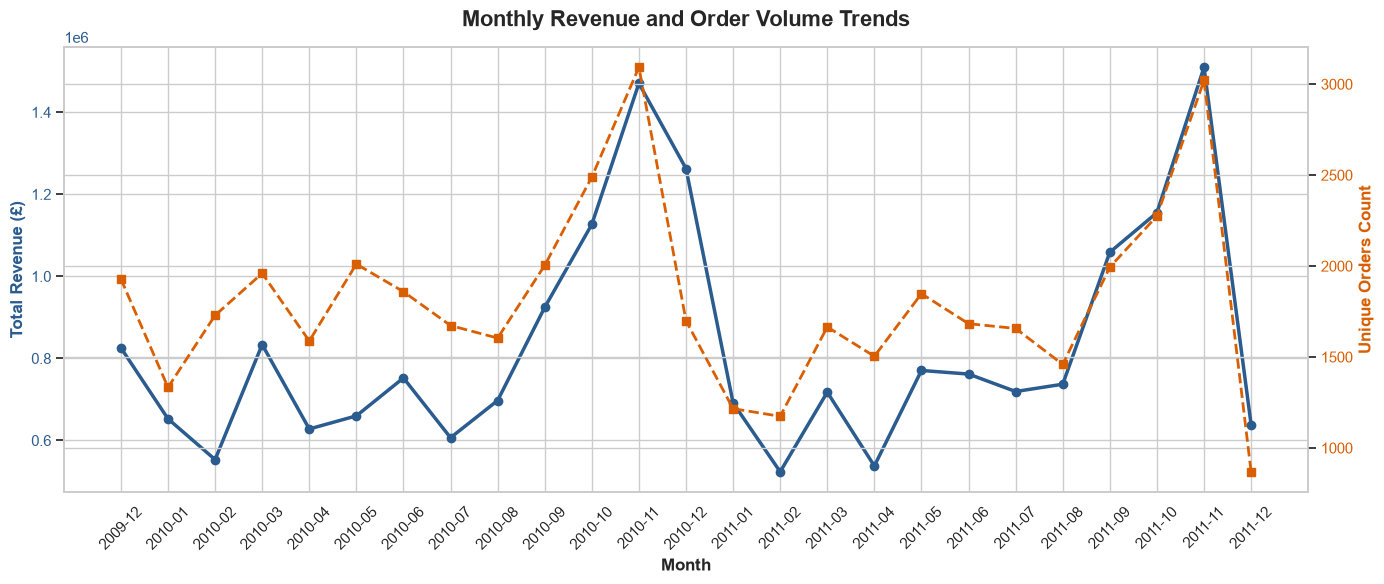

In [33]:
monthly_summary = df[~is_cancelled].groupby('YearMonth').agg(
    TotalRevenue=('TotalAmount', 'sum'),
    OrderCount=('Invoice', 'nunique')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 6))

color1 = '#2b5c8f'
ax1.set_title('Monthly Revenue and Order Volume Trends', fontsize=16, fontweight='bold', pad=15)
ax1.plot(monthly_summary['YearMonth'], monthly_summary['TotalRevenue'], color=color1, marker='o', linewidth=2.5, label='Revenue (£)')
ax1.set_xlabel('Month', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Revenue (£)', color=color1, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticklabels(monthly_summary['YearMonth'], rotation=45)

# Secondary axis for order count
ax2 = ax1.twinx()
color2 = '#d95f02'
ax2.plot(monthly_summary['YearMonth'], monthly_summary['OrderCount'], color=color2, marker='s', linestyle='--', linewidth=2, label='Order Count')
ax2.set_ylabel('Unique Orders Count', color=color2, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)

plt.tight_layout()
plt.show()

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\3259074084.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=day_counts.index, y=day_counts.values, ax=axes[0], palette='Blues_r')


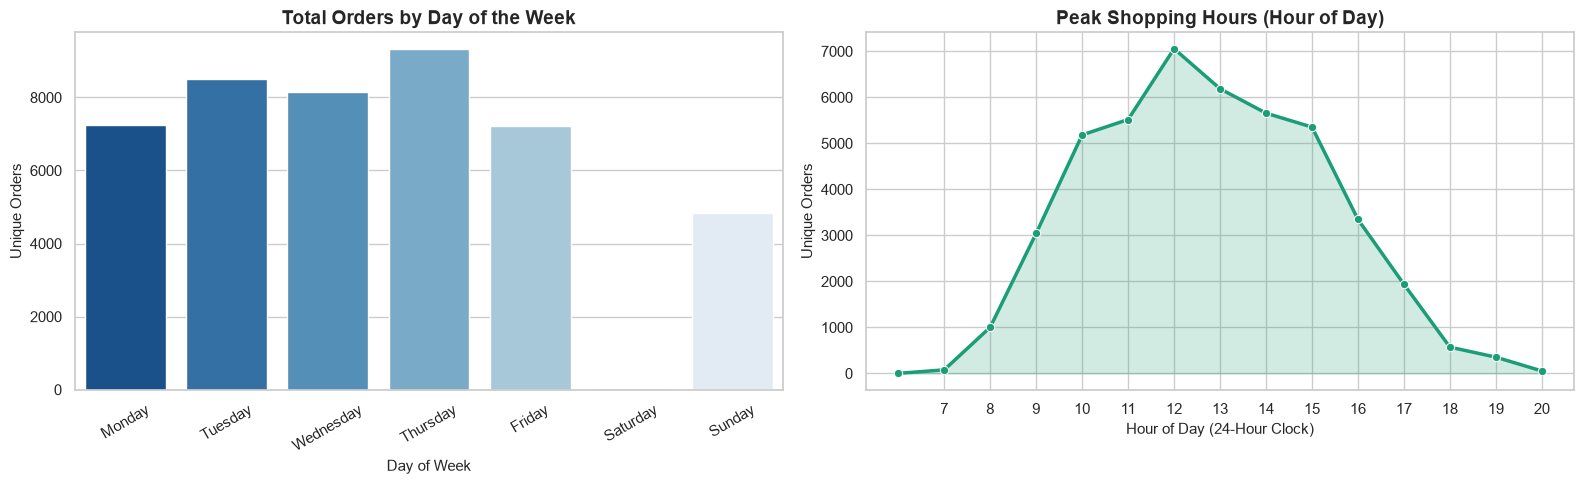

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Orders by Day of Week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df[~is_cancelled].groupby('DayOfWeek')['Invoice'].nunique().reindex(day_order).fillna(0)

sns.barplot(x=day_counts.index, y=day_counts.values, ax=axes[0], palette='Blues_r')
axes[0].set_title('Total Orders by Day of the Week', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Day of Week', fontsize=11)
axes[0].set_ylabel('Unique Orders', fontsize=11)
axes[0].tick_params(axis='x', rotation=30)

# 2. Orders by Hour of Day
hourly_counts = df[~is_cancelled].groupby('Hour')['Invoice'].nunique()
sns.lineplot(x=hourly_counts.index, y=hourly_counts.values, ax=axes[1], marker='o', color='#1b9e77', linewidth=2.5)
axes[1].fill_between(hourly_counts.index, hourly_counts.values, alpha=0.2, color='#1b9e77')
axes[1].set_title('Peak Shopping Hours (Hour of Day)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Hour of Day (24-Hour Clock)', fontsize=11)
axes[1].set_ylabel('Unique Orders', fontsize=11)
axes[1].set_xticks(range(7, 21))

plt.tight_layout()
plt.show()

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\110335014.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_cancelled_items.values, y=top_cancelled_items.index, ax=axes[1], palette='Reds_r')


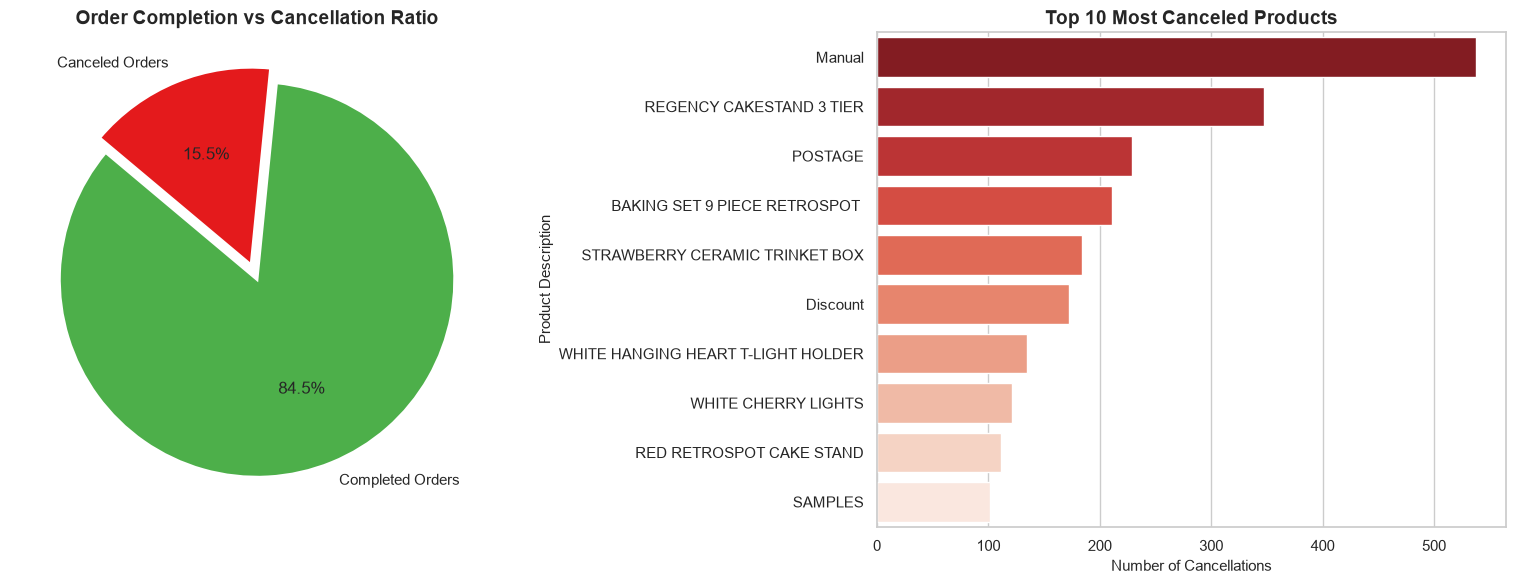

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Donut Chart: Completed vs Canceled Orders
total_inv = df['Invoice'].nunique()
cancelled_inv = df[is_cancelled]['Invoice'].nunique()
completed_inv = total_inv - cancelled_inv

axes[0].pie(
    [completed_inv, cancelled_inv], 
    labels=['Completed Orders', 'Canceled Orders'],
    autopct='%1.1f%%', 
    colors=['#4daf4a', '#e41a1c'], 
    startangle=140, 
    explode=(0, 0.08),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Order Completion vs Cancellation Ratio', fontsize=14, fontweight='bold')

# 2. Top 10 Most Frequently Returned / Canceled Products
top_cancelled_items = (
    df[is_cancelled]['Description']
    .value_counts()
    .dropna()
    .head(10)
)

sns.barplot(x=top_cancelled_items.values, y=top_cancelled_items.index, ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 10 Most Canceled Products', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Number of Cancellations', fontsize=11)
axes[1].set_ylabel('Product Description', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\3078538488.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=order_bins, ax=axes[1], palette='Purples_r')


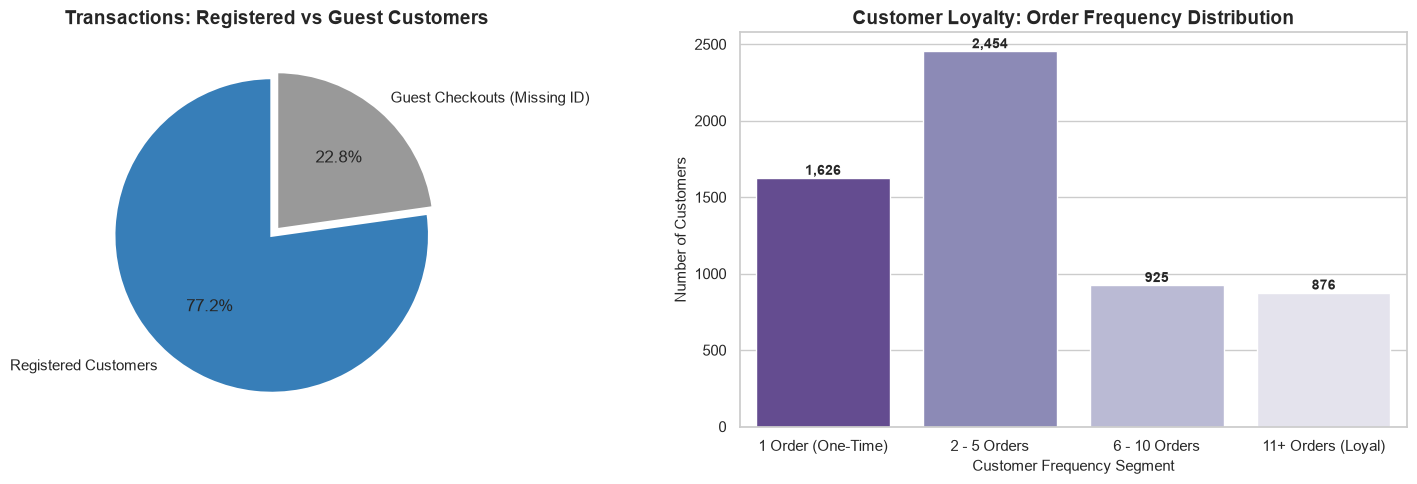

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Registered Customers vs Guest Checkouts
guest_count = len(df[df['Customer ID'].isin([0, np.nan])])
registered_count = len(df) - guest_count

axes[0].pie(
    [registered_count, guest_count], 
    labels=['Registered Customers', 'Guest Checkouts (Missing ID)'],
    autopct='%1.1f%%', 
    colors=['#377eb8', '#999999'], 
    startangle=90,
    explode=(0.05, 0),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Transactions: Registered vs Guest Customers', fontsize=14, fontweight='bold')

# 2. Purchase Frequency Distribution (Excluding Guests)
valid_cust = df[(df['Customer ID'].notnull()) & (df['Customer ID'] != 0) & (~is_cancelled)]
orders_per_customer = valid_cust.groupby('Customer ID')['Invoice'].nunique()

# Segment customer orders (1, 2-5, 6-10, 11+)
order_bins = pd.cut(
    orders_per_customer, 
    bins=[0, 1, 5, 10, np.inf], 
    labels=['1 Order (One-Time)', '2 - 5 Orders', '6 - 10 Orders', '11+ Orders (Loyal)']
)

sns.countplot(x=order_bins, ax=axes[1], palette='Purples_r')
axes[1].set_title('Customer Loyalty: Order Frequency Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Customer Frequency Segment', fontsize=11)
axes[1].set_ylabel('Number of Customers', fontsize=11)

for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height() + 20),
                     ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\3527977864.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_qty_items.values, y=top_qty_items.index, ax=axes[0], palette='crest')
C:\Users\mosa\AppData\Local\Temp\ipykernel_148\3527977864.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_rev_items.values, y=top_rev_items.index, ax=axes[1], palette='flare')


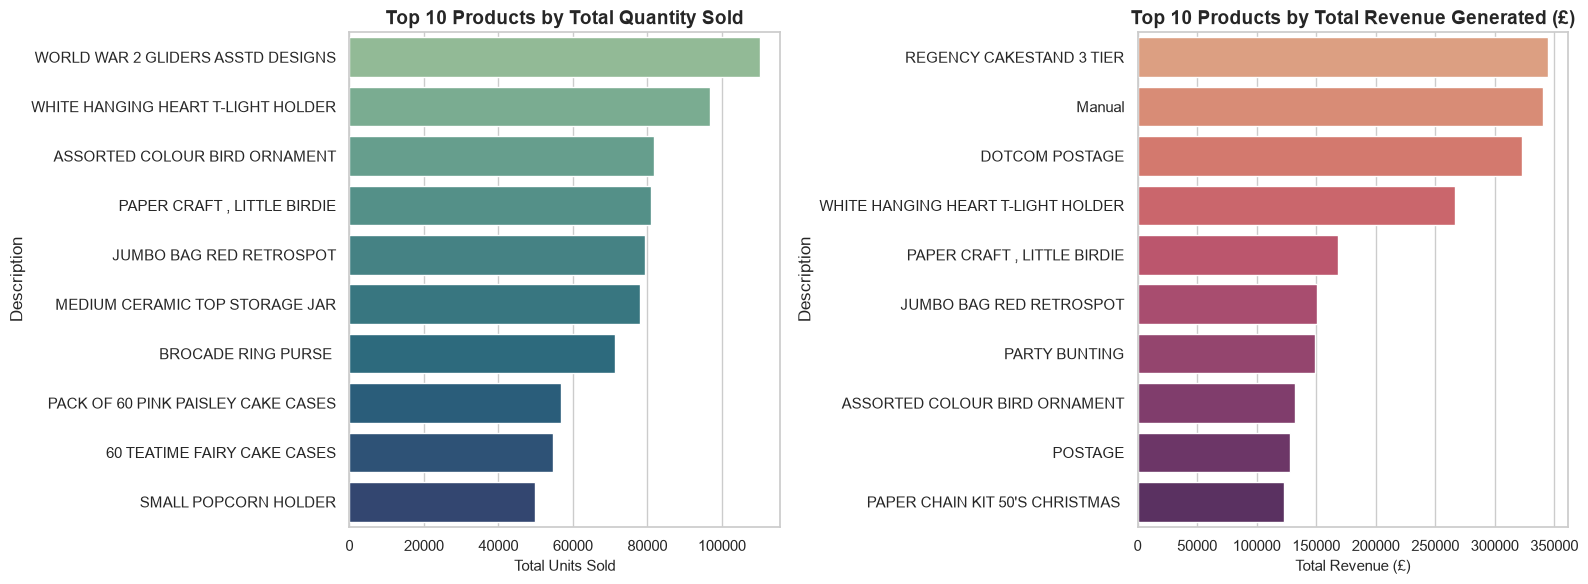

In [37]:
clean_sales = df[(~is_cancelled) & (df['Quantity'] > 0) & (df['Price'] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Top 10 Products by Quantity Sold
top_qty_items = clean_sales.groupby('Description')['Quantity'].sum().nlargest(10)
sns.barplot(x=top_qty_items.values, y=top_qty_items.index, ax=axes[0], palette='crest')
axes[0].set_title('Top 10 Products by Total Quantity Sold', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Units Sold', fontsize=11)

# 2. Top 10 Products by Total Revenue Generated
top_rev_items = clean_sales.groupby('Description')['TotalAmount'].sum().nlargest(10)
sns.barplot(x=top_rev_items.values, y=top_rev_items.index, ax=axes[1], palette='flare')
axes[1].set_title('Top 10 Products by Total Revenue Generated (£)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Revenue (£)', fontsize=11)

plt.tight_layout()
plt.show()

C:\Users\mosa\AppData\Local\Temp\ipykernel_148\3190136003.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_international.values, y=top_international.index, ax=axes[1], palette='viridis')


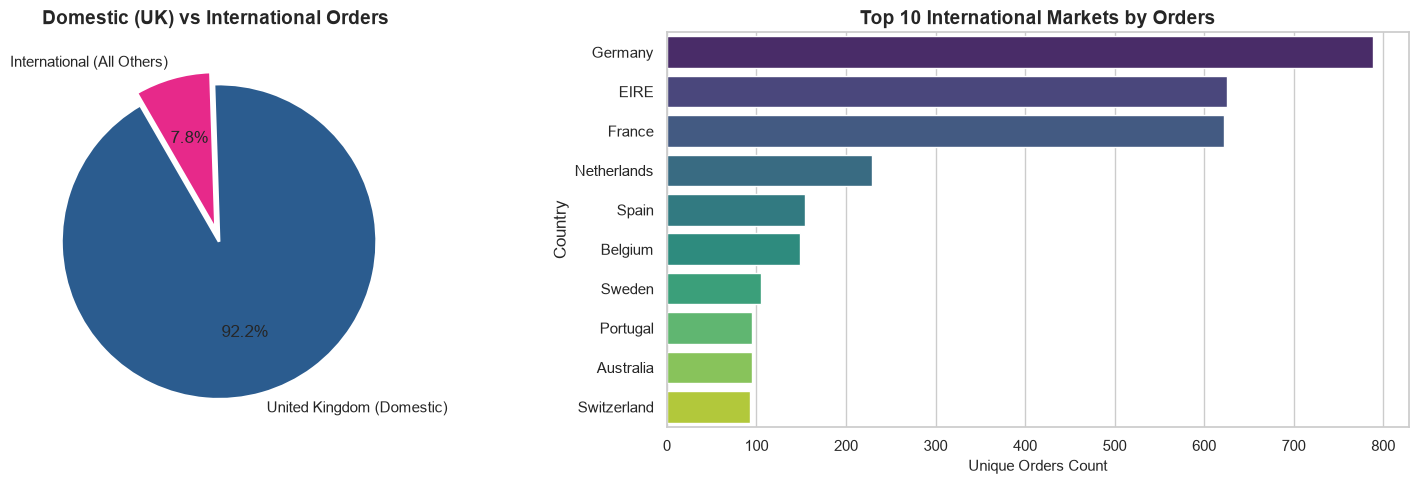

In [38]:
country_orders = df[~is_cancelled].groupby('Country')['Invoice'].nunique().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Overall Market Share: UK vs Rest of the World
uk_count = country_orders.get('United Kingdom', 0)
row_count = country_orders.sum() - uk_count

axes[0].pie(
    [uk_count, row_count],
    labels=['United Kingdom (Domestic)', 'International (All Others)'],
    autopct='%1.1f%%',
    colors=['#2b5c8f', '#e7298a'],
    startangle=120,
    explode=(0.08, 0),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[0].set_title('Domestic (UK) vs International Orders', fontsize=14, fontweight='bold')

# 2. Top 10 International Export Markets (Excluding UK)
top_international = country_orders.drop('United Kingdom', errors='ignore').head(10)
sns.barplot(x=top_international.values, y=top_international.index, ax=axes[1], palette='viridis')
axes[1].set_title('Top 10 International Markets by Orders', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Unique Orders Count', fontsize=11)

plt.tight_layout()
plt.show()